# Laboratório completo: séries temporais com dados públicos

Execute **Run → Run All Cells** no kernel **PUCPR Python 3.12**.
Este notebook treina e registra candidatos no MLflow; cada execução cria novos runs.
Não altera o catálogo acadêmico nem promove modelos para produção.

## Pergunta e origem
Conseguimos prever o próximo trimestre de PIB real, consumo real e desemprego?
Usamos 203 trimestres (1959Q1–2009Q3) da base `macrodata`, distribuída com
statsmodels 0.14.4. Dados históricos públicos FRED/BLS, compilados por Skipper Seabold.
[Fonte, dicionário e declaração de domínio público](https://github.com/statsmodels/statsmodels/blob/v0.14.4/statsmodels/datasets/macrodata/data.py).
PIB/consumo estão em bilhões de dólares de 2005; desemprego em percentual.
É um benchmark técnico: não representa alunos, matrículas ou previsão econômica atual.
Usa dados revisados disponíveis na base, não vintages de publicação em tempo real.

In [1]:
from pathlib import Path
import hashlib, json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from statsmodels.datasets import macrodata
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import mlflow
import mlflow.sklearn
from mlflow.models import infer_signature

OUTPUT = Path('/workspace/public-demo')
OUTPUT.mkdir(parents=True, exist_ok=True)
EXPERIMENT = 'public-macrodata-timeseries'
mlflow.set_tracking_uri(os.environ['MLFLOW_TRACKING_URI'])
experiment = mlflow.set_experiment(EXPERIMENT)
print('Experimento:', EXPERIMENT, '| ID:', experiment.experiment_id)

2026/10/23 21:25:59 INFO mlflow.tracking.fluent: Experiment with name 'public-macrodata-timeseries' does not exist. Creating a new experiment.


Experimento: public-macrodata-timeseries | ID: 2


## 1. Carregar, validar e preservar a base
O CSV já está instalado no pacote; não há download nem dados inventados.
Salvamos uma cópia com SHA-256 para rastrear exatamente a entrada de cada execução.

In [2]:
raw = macrodata.load_pandas().data.copy()
periods = pd.PeriodIndex(raw.year.astype(int).astype(str) + 'Q' + raw.quarter.astype(int).astype(str), freq='Q')
raw.index = periods.to_timestamp(how='start')
raw.index.name = 'date'
assert len(raw) == 203 and raw.index.is_unique and raw.index.is_monotonic_increasing
assert not raw.isna().any().any()
assert np.all(np.diff(periods.asi8) == 1), 'Lacuna temporal'
csv_path = OUTPUT / 'macrodata.csv'
raw.to_csv(csv_path, float_format='%.10g')
checksum = hashlib.sha256(csv_path.read_bytes()).hexdigest()
provenance = dict(dataset='statsmodels.macrodata', version='0.14.4', sha256=checksum,
    source='https://github.com/statsmodels/statsmodels/blob/v0.14.4/statsmodels/datasets/macrodata/data.py',
    license='Public domain (dataset declaration)', rows=len(raw), frequency='quarterly')
(OUTPUT / 'provenance.json').write_text(json.dumps(provenance, indent=2))
print('Linhas:', len(raw), '| Período:', periods[0], 'até', periods[-1], '| SHA256:', checksum)
display(raw.head())
display(raw[['realgdp', 'realcons', 'unemp']].describe())

Linhas: 203 | Período: 1959Q1 até 2009Q3 | SHA256: ca842c7ff67ab3be58a9c8dd451b5eea6e0954f2c84112b39a40bd96e5deb6f1


,year,quarter,realgdp,realcons,realinv,realgovt,realdpi,cpi,m1,tbilrate,unemp,pop,infl,realint
date,,,,,,,,,,,,,,
1959-01-01,1959.0,1.0,2710.349,1707.4,286.898,470.045,1886.9,28.98,139.7,2.82,5.8,177.146,0.00,0.00
1959-04-01,1959.0,2.0,2778.801,1733.7,310.859,481.301,1919.7,29.15,141.7,3.08,5.1,177.830,2.34,0.74
1959-07-01,1959.0,3.0,2775.488,1751.8,289.226,491.260,1916.4,29.35,140.5,3.82,5.3,178.657,2.74,1.09
1959-10-01,1959.0,4.0,2785.204,1753.7,299.356,484.052,1931.3,29.37,140.0,4.33,5.6,179.386,0.27,4.06
1960-01-01,1960.0,1.0,2847.699,1770.5,331.722,462.199,1955.5,29.54,139.6,3.50,5.2,180.007,2.31,1.19


,realgdp,realcons,unemp
count,203.000000,203.000000,203.000000
mean,7221.171901,4825.293103,5.884729
std,3214.956044,2313.346192,1.458574
min,2710.349000,1707.400000,3.400000
25%,4440.103500,2874.100000,4.900000
50%,6559.594000,4299.900000,5.700000
75%,9629.346500,6398.150000,6.800000
max,13415.266000,9363.600000,10.700000


## 2. Explorar tendências e variações
Cada variável tem escala própria. Não comparamos MAE de dólares com MAE em pontos percentuais.
Observe a tendência de PIB/consumo e os ciclos de desemprego.

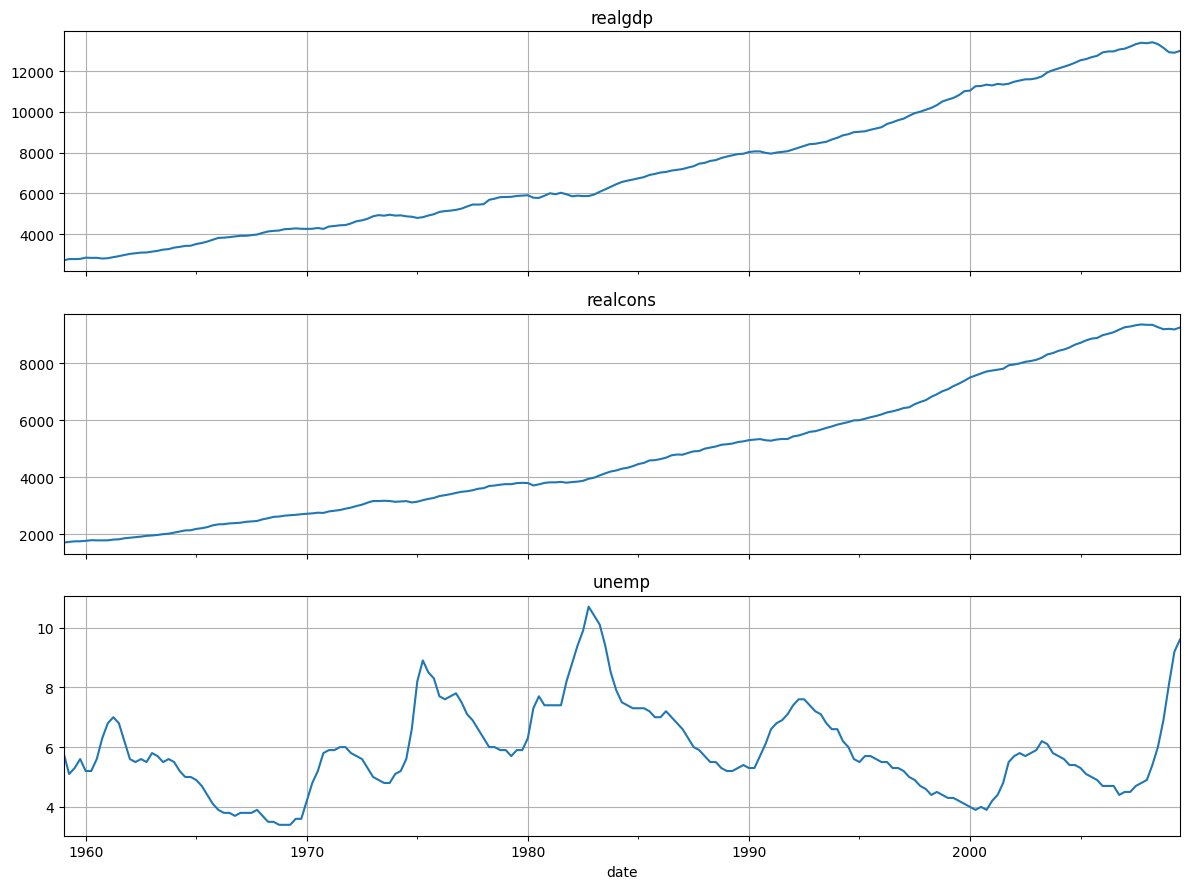

In [3]:
SERIES = ['realgdp', 'realcons', 'unemp']
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for name, ax in zip(SERIES, axes):
    raw[name].plot(ax=ax, title=name, grid=True)
fig.tight_layout()
fig.savefig(OUTPUT / 'historical-series.png', dpi=140)
plt.show()

## 3. Features e protocolo temporal
Para prever y(t), usamos apenas y(t-1), y(t-2), y(t-4), média dos quatro trimestres
anteriores e mudança anterior. Nenhum valor contemporâneo de outra série entra no modelo.
Os últimos 20 trimestres são teste; os 20 anteriores são validação.
Escolhemos o método por MAE de validação e só depois observamos o teste.
A avaliação é de **um passo à frente**: valores reais de trimestres já encerrados
ficam disponíveis no próximo passo. Não equivale a prever 20 trimestres de uma vez.

In [4]:
FEATURES = ['lag1', 'lag2', 'lag4', 'mean4', 'previous_change']
def supervised(series):
    frame = pd.DataFrame({'y': series})
    for lag in (1, 2, 4):
        frame[f'lag{lag}'] = series.shift(lag)
    frame['mean4'] = series.shift(1).rolling(4).mean()
    frame['previous_change'] = series.shift(1).diff()
    return frame.dropna()

def estimator(name):
    if name == 'ridge':
        return make_pipeline(StandardScaler(), Ridge(alpha=1.0))
    return RandomForestRegressor(n_estimators=100, max_depth=6, min_samples_leaf=3,
                                 random_state=42, n_jobs=1)

def metrics(actual, predicted):
    return {'mae': float(mean_absolute_error(actual, predicted)),
            'rmse': float(np.sqrt(mean_squared_error(actual, predicted)))}

sample = supervised(raw.realgdp)
display(sample.head())
print('Treino:', len(sample)-40, '| Validação: 20 | Teste: 20')
assert sample.index[-41] < sample.index[-40] < sample.index[-20]
assert sample.lag1.iloc[0] == raw.realgdp.iloc[3]

,y,lag1,lag2,lag4,mean4,previous_change
date,,,,,,
1960-01-01,2847.699,2785.204,2775.488,2710.349,2762.46050,9.716
1960-04-01,2834.390,2847.699,2785.204,2778.801,2796.79800,62.495
1960-07-01,2839.022,2834.390,2847.699,2775.488,2810.69525,-13.309
1960-10-01,2802.616,2839.022,2834.390,2785.204,2826.57875,4.632
1961-01-01,2819.264,2802.616,2839.022,2847.699,2830.93175,-36.406


Treino: 159 | Validação: 20 | Teste: 20


## 4. Treinar e comparar nove execuções
Baseline de persistência: próximo valor = último valor observado.
Ridge aplica padronização ajustada somente no treino; Random Forest usa semente fixa.
Após validação, cada estimador é reajustado em treino+validação para medir o teste.
Registramos métricas, parâmetros, dados, gráficos, previsões e seis modelos sklearn
no experimento público. Baseline não precisa de artefato treinado.

In [5]:
records, all_predictions, run_links = [], {}, []
for series_name in SERIES:
    frame = supervised(raw[series_name])
    train, valid, test = frame.iloc[:-40], frame.iloc[-40:-20], frame.iloc[-20:]
    candidates = {}
    for algorithm in ('persistence', 'ridge', 'random_forest'):
        model = None if algorithm == 'persistence' else estimator(algorithm)
        if model is None:
            val_prediction = valid.lag1.to_numpy()
        else:
            model.fit(train[FEATURES], train.y)
            val_prediction = model.predict(valid[FEATURES])
        candidates[algorithm] = metrics(valid.y, val_prediction)
    selected = min(candidates, key=lambda name: candidates[name]['mae'])
    predictions = pd.DataFrame({'actual': test.y})
    for algorithm, validation_metrics in candidates.items():
        with mlflow.start_run(run_name=f'{series_name}-{algorithm}', tags={
            'dataset': 'public-macrodata', 'synthetic': 'false', 'purpose': 'demonstration',
            'selected_on_validation': str(algorithm == selected).lower(), 'dataset_sha256': checksum}) as run:
            mlflow.log_params(dict(series=series_name, algorithm=algorithm, horizon=1,
                train_rows=len(train), validation_rows=20, test_rows=20,
                split='chronological', selection_metric='validation_mae', seed=42,
                features=','.join(FEATURES)))
            model = None if algorithm == 'persistence' else estimator(algorithm)
            if model is None:
                predicted = test.lag1.to_numpy()
            else:
                fit = frame.iloc[:-20]
                model.fit(fit[FEATURES], fit.y)
                predicted = model.predict(test[FEATURES])
                mlflow.log_params({f'model_{k}': str(v) for k, v in model.get_params().items()})
                mlflow.sklearn.log_model(model, name='model',
                    signature=infer_signature(test[FEATURES], predicted),
                    input_example=test[FEATURES].head(2),
                    registered_model_name=f'public-macrodata-{series_name}-{algorithm}')
            test_metrics = metrics(test.y, predicted)
            mlflow.log_metrics({f'validation_{k}': v for k,v in validation_metrics.items()})
            mlflow.log_metrics({f'test_{k}': v for k,v in test_metrics.items()})
            mlflow.log_artifact(str(csv_path), 'dataset')
            mlflow.log_artifact(str(OUTPUT / 'provenance.json'), 'dataset')
            mlflow.log_artifact(str(OUTPUT / 'historical-series.png'), 'plots')
            detail = pd.DataFrame({'actual': test.y, 'predicted': predicted})
            detail['residual'] = detail.actual - detail.predicted
            prediction_path = OUTPUT / f'{series_name}-{algorithm}-predictions.csv'
            detail.to_csv(prediction_path)
            mlflow.log_artifact(str(prediction_path), 'evaluation')
            fig, ax = plt.subplots(figsize=(10, 3))
            detail[['actual', 'predicted']].plot(ax=ax, title=f'{series_name}: {algorithm}', grid=True)
            fig.tight_layout()
            mlflow.log_figure(fig, 'plots/test-predictions.png')
            plt.close(fig)
            predictions[algorithm] = predicted
            records.append(dict(series=series_name, algorithm=algorithm,
                validation_mae=validation_metrics['mae'], test_mae=test_metrics['mae'],
                test_rmse=test_metrics['rmse'], selected=algorithm == selected, run_id=run.info.run_id))
            run_links.append(f'http://127.0.0.1:5000/#/experiments/{experiment.experiment_id}/runs/{run.info.run_id}')
    all_predictions[series_name] = predictions
results = pd.DataFrame(records)
results.to_csv(OUTPUT / 'comparison.csv', index=False)
display(results.drop(columns='run_id').round(3))
assert len(results) == 9 and np.isfinite(results[['validation_mae','test_mae','test_rmse']]).all().all()

2026/10/23 21:26:00 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git SHA is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet



2026/10/23 21:26:00 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run realgdp-persistence at: http://mlflow.mlops.svc.cluster.local:5000/#/experiments/2/runs/282c3af6380946ef84625c971b1c4690
🧪 View experiment at: http://mlflow.mlops.svc.cluster.local:5000/#/experiments/2


2026/10/23 21:26:03 INFO mlflow.models.model: Found the following environment variables used during model inference: [API_TOKEN]. Please check if you need to set them when deploying the model. To disable this message, set environment variable `MLFLOW_RECORD_ENV_VARS_IN_MODEL_LOGGING` to `false`.


Successfully registered model 'public-macrodata-realgdp-ridge'.
2026/10/23 21:26:03 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: public-macrodata-realgdp-ridge, version 1


Created version '1' of model 'public-macrodata-realgdp-ridge'.


... (20 outputs left out)

Successfully registered model 'public-macrodata-unemp-random_forest'.
2026/10/23 21:26:15 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: public-macrodata-unemp-random_forest, version 1


Created version '1' of model 'public-macrodata-unemp-random_forest'.


🏃 View run unemp-random_forest at: http://mlflow.mlops.svc.cluster.local:5000/#/experiments/2/runs/45ea4c27df7f4bce9b4d2f44dc32a283
🧪 View experiment at: http://mlflow.mlops.svc.cluster.local:5000/#/experiments/2


,series,algorithm,validation_mae,test_mae,test_rmse,selected
0,realgdp,persistence,81.036,88.155,103.205,False
1,realgdp,ridge,63.220,82.008,110.550,True
2,realgdp,random_forest,1090.205,949.950,992.861,False
3,realcons,persistence,63.470,54.000,61.877,False
4,realcons,ridge,30.120,53.202,71.484,True
5,realcons,random_forest,979.844,732.765,764.581,False
6,unemp,persistence,0.190,0.310,0.474,False
7,unemp,ridge,0.166,0.210,0.274,False
8,unemp,random_forest,0.166,0.264,0.355,True


## 5. Interpretar o teste e consultar o Registry
O melhor na validação pode perder no teste; mantenha a seleção original para evitar
escolher retrospectivamente pelo teste. A base pequena e as mudanças econômicas
limitam a generalização. Random Forest não extrapola tendências tão bem quanto modelos lineares.
Os registros `public-macrodata-*` são candidatos de demonstração, sem alias champion.

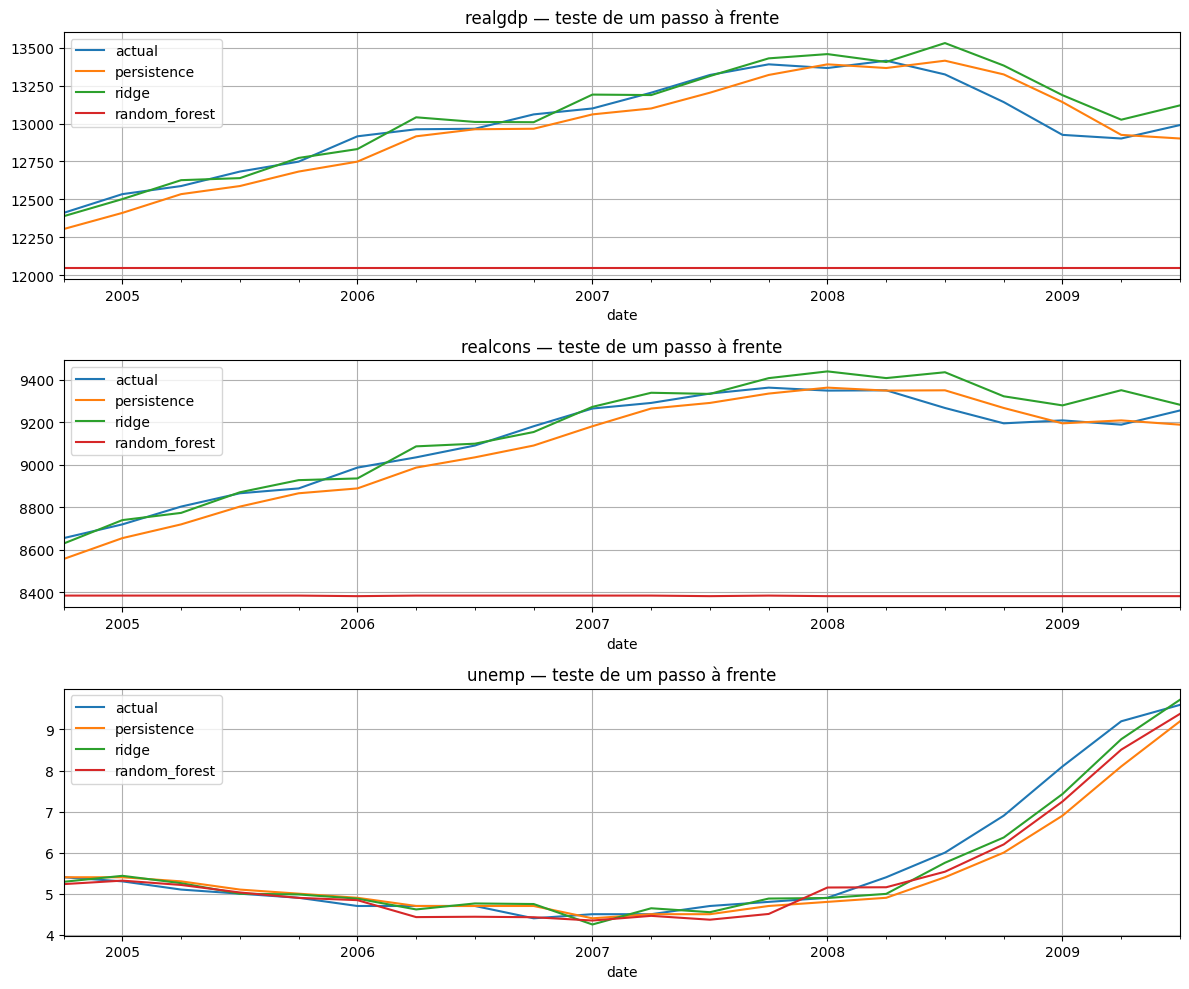

,series,algorithm,validation_mae,test_mae,test_rmse,selected
1,realgdp,ridge,63.220,82.008,110.550,True
4,realcons,ridge,30.120,53.202,71.484,True
8,unemp,random_forest,0.166,0.264,0.355,True


[Abrir experimento público](http://127.0.0.1:5000/#/experiments/2)

9 runs finalizados; 6 modelos registrados; sem promoção automática.
CSV, proveniência, previsões e figuras em /workspace/public-demo


In [6]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10))
for (name, prediction), ax in zip(all_predictions.items(), axes):
    prediction.plot(ax=ax, title=f'{name} — teste de um passo à frente', grid=True)
fig.tight_layout()
fig.savefig(OUTPUT / 'comparison.png', dpi=140)
plt.show()
display(results[results.selected].drop(columns='run_id').round(3))
display(Markdown(f'[Abrir experimento público](http://127.0.0.1:5000/#/experiments/{experiment.experiment_id})'))
print('9 runs finalizados; 6 modelos registrados; sem promoção automática.')
print('CSV, proveniência, previsões e figuras em', OUTPUT)

## Próximos exercícios
1. Compare janela expansiva com janela móvel, mantendo o teste final intocado.
2. Experimente prever diferenças e reconstruir os níveis; compare contra persistência.
3. Adicione horizontes maiores com estratégia recursiva e métricas por horizonte.
4. Para o caso Marista, obtenha séries históricas institucionais autorizadas; este
benchmark demonstra o fluxo de trabalho, não valida desempenho em matrículas.

Os experimentos acadêmicos existentes estão em
[pucpr-synthetic](http://127.0.0.1:5000/#/experiments/1).